# A carrier-depletion p–n junction phase shifter

The purpose of this notebook is to illustrate the physics that drive silicon photonic devices using simple, tractable models: from the electrostatics of the abrupt junction, through the optical properties of doped silicon, to the lateral modes of a ridge waveguide and the phase shift caused by the depletion region.

**Conventions**
- Units: lengths in µm, carrier densities in cm⁻³, voltages in V. Permittivities are *relative* (dimensionless) unless stated otherwise.
- Geometry: the junction is at $x=0$ with the $p$ side at $x<0$. The depletion region occupies $[-x_p,\,x_n]$ with $x_p, x_n > 0$.
- Bias: `v_bias` $>0$ is forward bias, $<0$ is reverse bias.
- Time dependence $e^{-i\omega t}$: $\Im\varepsilon_r>0$ means loss, $n+ik=\sqrt{\varepsilon_r}$ with $k>0$, and modes propagate as $e^{i\beta z}$ with $\Im\beta>0$ meaning attenuation.
- Naming: constants and fixed parameters are `UPPER_CASE`; functions and arrays are `snake_case`. Subscripts: `p`, `n` (doped sides), `d` (depleted), `ox` (oxide), `opt` (optical frequency).

## Semiconductors

In solids, electrons occupy _states_ that are characterized by a continuous vector parameter $\mathbf{k}$. The energies of these states, $\epsilon(\mathbf{k})$, arise as eigenvalues of the system's Hamiltonian and thus have some multiplicity. Roughly speaking, each continuous function $\epsilon_b(\mathbf{k})$ is called a _band_.

In semiconductors, the highest-energy occupied band and the lowest-energy empty (at zero temperature) band are approximately parabolic near the local maximum/minimum. This makes electrons subject to the crystal field behave like free charges with an effective mass given by the curvature of the bands. Therefore, electrical properties of bulk semiconductors can be approximated by the Drude model.

At **thermal equilibrium**, the number of electrons (per unit volume, $n$) in the conduction band (C) is given by the Fermi distribution,

$$ n = N_C \exp \left(-\frac{E_C  - E_F}{kT}\right). $$

Similarly, for the hole density ($p$) in the valence band (V),

$$ p = N_V \exp \left(\frac{E_V  - E_F}{kT}\right). $$

Here, $N_C$ and $N_V$ are the effective densities of states in each band and $E_C$ ($E_V$) is the minimum (maximum) energy of the conduction (valence) band. Although these values depend on the temperature, their typical variation is small compared with the exponential and will be treated as constants.

### Intrinsic semiconductor

In intrinsic (undoped) semiconductors, the only source of free carriers is the creation of electron-hole pairs when electrons are promoted from the valence band, creating an equal number of holes, $p = n$. This defines the intrinsic carrier density $n_i$ by

$$n_i^2 = p\,n = N_V N_C \exp \left(-\frac{E_g}{kT}\right), $$

where $E_g = E_C-E_V$ is the _energy gap_ between bands, and the intrinsic Fermi level is

$$ E_i =   \frac{E_V + E_C}{2} + \frac{kT}{2} \log \left(\frac{N_V}{N_C}\right).$$

### Extrinsic semiconductor

Dopants introduce new energy levels within the band gap, while changing the total number of electrons in the system: _donors_ add one extra electron per atom and create a donor level $E_D \lesssim E_C$, while _acceptors_ add one electron less and create an acceptor level $E_A \gtrsim E_V$. These levels lie so close to the original bands that, for practical purposes, impurities are considered to be fully ionized. That is, the extra electrons from donors go to the conduction band and acceptors take one electron from the valence band, thus creating a hole.
Therefore, the **total charge density** for fully ionized impurities is

$$\rho = q (p - n + N_D - N_A),$$

where $N_D$ and $N_A$ are the donor and acceptor densities.

At equilibrium, neutrality implies $\rho = 0$ and the mass-action law forces $pn = n_i^2$, even when $p,n \neq n_i$. Let $C = N_D-N_A$ be the net doping; then the equilibrium carrier densities $n_0$, $p_0$ are given by

$$\frac{n_i^2}{n_0} - n_0 + C = 0 \Rightarrow n_0 = \frac{1}{2} \left( {\sqrt{C^2+4 n_i^2} + C}\right), $$

$$p_0 -\frac{n_i^2}{p_0} + C = 0 \Rightarrow p_0 = \frac{1}{2} \left( {\sqrt{C^2+4 n_i^2} - C}\right). $$

### Non-homogeneous semiconductor: the depletion approximation

If doping is not uniform, carrier gradients lead to diffusion currents: electrons from the $n$ region diffuse into the $p$ region, while holes diffuse in the opposite direction breaking charge neutrality. Then an electrostatic potential $\phi$ builds up, shifting the energy bands accordingly, $\epsilon \to \epsilon - q \phi$. Excess carriers are eliminated by electron-hole recombination until chemical imbalance is compensated by the electrostatic energy and a new equilibrium is reached when the built-in potential difference is
$$ \phi = V_{bi} = \frac{kT}{q} \log \left( \frac{p_0^{(p)}\, n_0^{(n)}}{n_i^2}  \right),$$
where $p_0^{(p)}$ and $n_0^{(n)}$ are the equilibrium carrier densities in the extrinsic semiconductors (far from the junction).

A rigurous treatment of the problem requires finding numerical solutions to coupled differential equations. In the following, however, two simplifying assumptions  will be done so that a semianalytical treatment can be carried out[<sup>[1]</sup>](#sze), which provides a good approximation to the full problem:
- free carriers are assumed to vanish completely inside a depletion region $-x_p < x < x_n$;
- carrier densities take their equilibrium values $n_0$, $p_0$ outside the depletion region.

<a name="sze"></a>1. S. M. Sze, _Physics of Semiconductor Devices_ (John Wiley & Sons, 1969)

## An abrupt junction

The simplest structure is the abrupt junction, where net doping $C = -N_A$ for $x < 0$ ($p$ side) and $C = +N_D$ for $x > 0$ ($n$ side). Under the depletion approximation, the charge density becomes piecewise constant,

$$\rho(x) = \begin{cases} -q ~ N_A & -x_p< x < 0, \\ +q ~N_D & 0 < x < x_n, \\ 0 & \text{otherwise.} \end{cases},$$
with the limits of the depletion region such that global neutrality is preserved ($N_A ~ x_p = N_D ~ x_n$).

The electrostatic potential can be obtained from $\rho$ by integrating Poisson's equation,
$$-\frac{\partial^2 \phi}{\partial x^2} = \frac{\rho}{\varepsilon_s}, \qquad \varepsilon_s = \varepsilon_r \varepsilon_0.$$
Hence, $\phi$ is piecewise parabolic and  the potential drop between the two neutral regions results
$$\Delta \phi = \frac{q}{2\varepsilon_s}\left(N_A x_p^2 + N_D x_n^2\right),$$
with $\Delta \phi = V_{bi}-v$ for an applied bias $v < V_{bi}$ (positive for forward bias) and $V_{bi} \simeq V_T \log\left(N_A N_D / n_i^2\right)$ with $V_T = kT/q$ (the thermal voltage).

The depletion region limits can be solved from the expressions above to obtain
$$x_n = \sqrt{\frac{2\varepsilon_s (V_{bi}-v)}{q}\,\frac{N_A}{N_D\,(N_A+N_D)}}, \qquad x_p = x_n\,\frac{N_D}{N_A}.$$
Then, the junction width is $W = x_p + x_n$ and the charge-voltage characteristic results in an effective junction capacitance per unit area is $C_j = \varepsilon_s/W$.

In [ ]:
import os
import urllib.request

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

# ---- Physical constants (SI) ----
Q_E = 1.602e-19            # elementary charge [C]
EPS_0 = 8.854e-12          # vacuum permittivity [F/m]
M_0 = 9.11e-31             # electron rest mass [kg]
C_LIGHT = 299792458.0      # speed of light [m/s]
V_T = 0.0259               # thermal voltage kT/q at 300 K [V]

# ---- Silicon parameters at 300 K ----
N_I = 1.6e10               # intrinsic carrier density [cm^-3]
EPS_R_SI_STATIC = 11.7     # static relative permittivity (electrostatics)
MU_N = 1000e-4             # electron mobility [m^2/(V s)] (for N = 2e16 cm^-3, Sze)
MU_P = 450e-4              # hole mobility [m^2/(V s)]
M_CE = 0.26 * M_0          # electron conductivity effective mass [kg]
M_CH = 0.38 * M_0          # hole conductivity effective mass [kg]

# ---- Doping [cm^-3] ----
N_A = 2e16                 # acceptors (p side)
N_D = 2e16                 # donors (n side)

# ---- Optical frequency ----
WAVELENGTH_UM = 1.55                               # vacuum wavelength [um]
K0_UM = 2 * np.pi / WAVELENGTH_UM                  # vacuum wavenumber [um^-1]
OMEGA_OPT = 2 * np.pi * C_LIGHT / (WAVELENGTH_UM * 1e-6)   # angular frequency [rad/s]

In [ ]:
def net_doping(x_um, n_a=N_A, n_d=N_D):
    """Net donor density C = N_D - N_A of the abrupt junction [cm^-3]."""
    return np.where(np.asarray(x_um) < 0, -n_a, n_d)


def equilibrium_densities(net_doping_cm3):
    """Equilibrium electron and hole densities (n0, p0) [cm^-3] for a net doping C.

    Neutrality + mass action: n0 - p0 = C and n0 p0 = n_i^2. The majority density is
    computed directly and the minority one from the mass-action law (no cancellation).
    """
    c = np.asarray(net_doping_cm3, dtype=float)
    majority = (np.sqrt(c**2 + 4 * N_I**2) + np.abs(c)) / 2
    minority = N_I**2 / majority
    return np.where(c >= 0, majority, minority), np.where(c >= 0, minority, majority)


def built_in_potential(n_a=N_A, n_d=N_D):
    """Built-in potential V_bi [V] of the abrupt junction."""
    return V_T * np.log(n_a * n_d / N_I**2)


def depletion_widths(v_bias=0.0, n_a=N_A, n_d=N_D):
    """Depletion widths (x_p, x_n) [um] in the depletion approximation.

    v_bias > 0 is forward bias. The widths tend to zero as v_bias -> V_bi.
    """
    v_total = np.clip(built_in_potential(n_a, n_d) - v_bias, 0.0, None)
    na, nd = n_a * 1e6, n_d * 1e6                                  # [m^-3]
    x_n = np.sqrt(2 * EPS_R_SI_STATIC * EPS_0 * v_total / Q_E * na / (nd * (na + nd)))   # [m]
    return 1e6 * x_n * nd / na, 1e6 * x_n


def junction_profile(x_um, v_bias=0.0, n_a=N_A, n_d=N_D):
    """Depletion-approximation profiles of the abrupt junction at positions x_um [um].

    Returns a dict with: n, p [cm^-3]; rho [C/cm^3]; field [V/cm]; phi [V]
    (phi = 0 in the neutral p region, phi = V_bi - v_bias in the neutral n region).
    """
    x_um = np.asarray(x_um, dtype=float)
    x_p, x_n = depletion_widths(v_bias, n_a, n_d)
    in_p = (x_um >= -x_p) & (x_um < 0)
    in_n = (x_um >= 0) & (x_um <= x_n)

    n0, p0 = equilibrium_densities(net_doping(x_um, n_a, n_d))
    n = np.where(in_p | in_n, N_I, n0)
    p = np.where(in_p | in_n, N_I, p0)

    eps_s = EPS_R_SI_STATIC * EPS_0 * 1e-2                         # [F/cm]
    xp_cm, xn_cm, x_cm = 1e-4 * x_p, 1e-4 * x_n, 1e-4 * x_um
    v_total = built_in_potential(n_a, n_d) - v_bias

    rho = np.where(in_p, -Q_E * n_a, 0.0) + np.where(in_n, Q_E * n_d, 0.0)
    field = (np.where(in_p, -Q_E * n_a * (x_cm + xp_cm) / eps_s, 0.0)
             + np.where(in_n, -Q_E * n_d * (xn_cm - x_cm) / eps_s, 0.0))
    phi = np.where(x_um < -x_p, 0.0,
          np.where(x_um < 0, Q_E * n_a * (x_cm + xp_cm)**2 / (2 * eps_s),
          np.where(x_um <= x_n, v_total - Q_E * n_d * (xn_cm - x_cm)**2 / (2 * eps_s), v_total)))
    return dict(n=n, p=p, rho=rho, field=field, phi=phi)


v_bi = built_in_potential()
x_p, x_n = depletion_widths(0.0)
print(f"Built-in potential: V_bi = {v_bi:.3f} V")
print(f"Depletion widths at zero bias: x_p = {x_p:.3f} um, x_n = {x_n:.3f} um, W = {x_p + x_n:.3f} um")

Built-in potential: V_bi = 0.727 V
Depletion widths at zero bias: x_p = 0.153 um, x_n = 0.153 um, W = 0.307 um


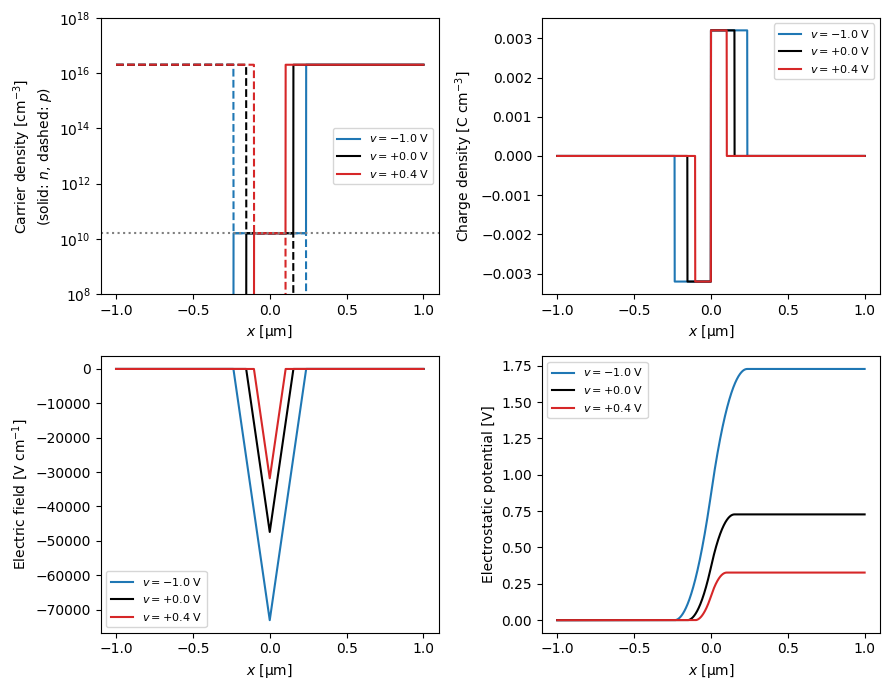

In [ ]:
# Abrupt junction at several biases (depletion approximation)
x_um = np.linspace(-1.0, 1.0, 4001)
biases = [(-1.0, "tab:blue"), (0.0, "black"), (0.4, "tab:red")]

fig, ax = plt.subplots(2, 2, figsize=(9, 7))
for v_bias, color in biases:
    prof = junction_profile(x_um, v_bias)
    label = f"$v={v_bias:+.1f}$ V"
    ax[0][0].plot(x_um, prof["n"], color=color, linestyle="-", label=label)
    ax[0][0].plot(x_um, prof["p"], color=color, linestyle="--")
    ax[0][1].plot(x_um, prof["rho"], color=color, label=label)
    ax[1][0].plot(x_um, prof["field"], color=color, label=label)
    ax[1][1].plot(x_um, prof["phi"], color=color, label=label)

ax[0][0].set_yscale("log")
ax[0][0].set_ylim(1e8, 1e18)
ax[0][0].axhline(N_I, color="gray", linestyle=":")
ax[0][0].set_ylabel("Carrier density [cm$^{-3}$]\n(solid: $n$, dashed: $p$)")
ax[0][1].set_ylabel("Charge density [C cm$^{-3}$]")
ax[1][0].set_ylabel("Electric field [V cm$^{-1}$]")
ax[1][1].set_ylabel("Electrostatic potential [V]")
for a in ax.ravel():
    a.set_xlabel("$x$ [µm]")
    a.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Optical properties

Silicon photonics operates primarily across the near-infrared (NIR) and mid-infrared (mid-IR) spectra, spanning from 1.1 µm up to approximately 8.5 µm. The most prominent wavelengths used in fiber-optic telecommunications, data centers, and optical interconnects are 1310 nm (O-band) and 1550 nm (C-band).

In a typical dielectric medium the overall susceptibility arises from the superposition of contributions from multiple resonances corresponding to different transitions.

, $E_k = h \nu_k$. Below the resonance ($\nu \ll \nu_k$), only the real susceptibility contributes to the refractive index and it can be expanded as a sum over the various resonances, known as the Sellmeier equation,

$$n^2=\varepsilon_r = 1 + \chi' = 1 + \sum_k \frac{\chi_k}{1-(\lambda_k/\lambda)^2},$$

with $\lambda_k = c/\nu_k.$

Next,

In [ ]:
# Refractive index n and extinction coefficient k of crystalline silicon at 300 K
# Ref. D. Franta et al., Appl. Surf. Sci. 421, 405-419 (2017)
# https://refractiveindex.info/?shelf=main&book=Si&page=Franta-300K
FRANTA_URL = "https://refractiveindex.info/tmp/database/data/main/Si/nk/Franta-300K.csv"
FRANTA_FILE = "Franta-300K.csv"
if not os.path.exists(FRANTA_FILE):
    urllib.request.urlretrieve(FRANTA_URL, FRANTA_FILE)

wl_um, n_si = np.loadtxt(FRANTA_FILE, delimiter=",", skiprows=1, usecols=(0, 1), unpack=True, max_rows=4001)
wl_um, k_si = np.loadtxt(FRANTA_FILE, delimiter=",", skiprows=4004, usecols=(0, 1), unpack=True, max_rows=4001)

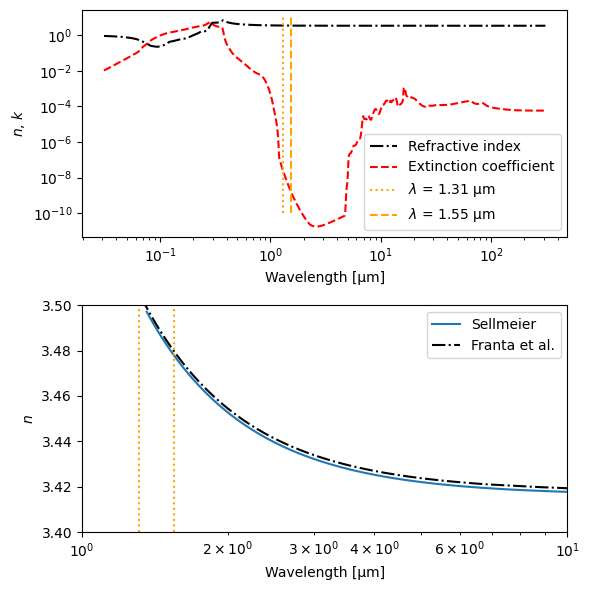

In [ ]:
# Sellmeier equation for silicon in the range 1.36-11 um (Fundamentals of Photonics)
SELLMEIER_LAMBDA_UM = np.array([0.3015, 1.1347, 1104.0])
SELLMEIER_CHI = np.array([10.6684, 0.0030, 1.5413])


def sellmeier_eps_r(wavelength_um):
    """Relative permittivity n^2 = 1 + sum_k chi_k / (1 - (lambda_k / lambda)^2)."""
    wavelength_um = np.atleast_1d(wavelength_um)[:, None]
    return 1 + np.sum(SELLMEIER_CHI / (1 - (SELLMEIER_LAMBDA_UM / wavelength_um)**2), axis=1)


wl_sellmeier_um = np.logspace(np.log10(1.36), np.log10(11), 100)

fig, axs = plt.subplots(2, 1, figsize=(6, 6))
axs[0].plot(wl_um, n_si, "-.", color="black", label="Refractive index")
axs[0].plot(wl_um, k_si, "--", color="red", label="Extinction coefficient")
axs[0].set_xscale("log")
axs[0].set_yscale("log")
axs[0].set_xlabel("Wavelength [µm]")
axs[0].set_ylabel(r"$n$, $k$")
axs[0].vlines([1.31], ymin=1e-10, ymax=10, color="orange", linestyle=":", label=r"$\lambda$ = 1.31 µm")
axs[0].vlines([1.55], ymin=1e-10, ymax=10, color="orange", linestyle="--", label=r"$\lambda$ = 1.55 µm")
axs[0].legend()

axs[1].plot(wl_sellmeier_um, np.sqrt(sellmeier_eps_r(wl_sellmeier_um)), label="Sellmeier")
axs[1].plot(wl_um, n_si, "-.", color="black", label="Franta et al.")
axs[1].set_xscale("log")
axs[1].set_xlabel("Wavelength [µm]")
axs[1].set_xlim(1, 10)
axs[1].set_ylim(3.4, 3.5)
axs[1].set_ylabel(r"$n$")
axs[1].vlines([1.31, 1.55], ymin=3.4, ymax=3.5, color="orange", linestyle=":")
axs[1].legend()
fig.tight_layout()
plt.show()

In [ ]:
# Relative permittivity of silicon from the different sources
# Optical value used below: Franta et al. at the operating wavelength, eps_r = (n + ik)^2
EPS_R_SI_OPT = np.interp(WAVELENGTH_UM, wl_um, n_si + 1j * k_si)**2

print("Static relative permittivity used for electrostatics:", EPS_R_SI_STATIC)
print("Sellmeier equation:")
print("\t- RF limit (outside its validity range):", 1 + SELLMEIER_CHI.sum())
print(f"\t- at {WAVELENGTH_UM} um:", sellmeier_eps_r(WAVELENGTH_UM)[0])
print("Franta et al.:")
print(f"\t- RF limit (longest tabulated wavelength, {wl_um[-1]:.1f} um):", n_si[-1]**2)
print(f"\t- at {WAVELENGTH_UM} um:", EPS_R_SI_OPT)

Static relative permittivity used for electrostatics: 11.7
Sellmeier equation:
	- RF limit (outside its validity range): 13.2127
	- at 1.55 um: 12.094390027824662
Franta et al.:
	- RF limit (longest tabulated wavelength, 310.0 um): 11.685215355642304
	- at 1.55 um: (12.107086347584355+9.796551943779182e-09j)


### Free-carrier contribution (Drude model)

In a (linear) conductive material, the combination of the dielectric and conductive properties can be represented by a complex, frequency-dependent relative permittivity. With time dependence $e^{-i\omega t}$,

$$ \varepsilon_r = \varepsilon_{r,\mathrm{Si}} + \frac{i\,\sigma(\omega)}{\varepsilon_0\,\omega},$$

where $\sigma$ is obtained from the Drude–Sommerfeld model,

$$\sigma(\omega) = \frac{N q^2 \tau}{m^*} \frac{1}{1 - i\omega \tau}.$$

In doped semiconductors, electrons and holes are modeled as carriers with effective masses $m^*$ ([ref](https://www.ioffe.ru/SVA/NSM/Semicond/Si/bandstr.html#Masses))

- $m^{*}_{ce}= 0.26\, m_0$
- $m^{*}_{ch}= 0.38\, m_0$

each contributing to the total conductivity, $\sigma = \sigma_n + \sigma_p$, with $N\to n$ or $p$ and $\tau\to\tau_e$ or $\tau_h$. Relaxation times follow from the mobility, $\mu = q \tau / m^*$. As the impurity concentration increases (at room temperature most impurities are ionized) the mobility decreases; the values used here correspond to $N = 2 \times 10^{16}$ cm$^{-3}$ (Sze) and are kept fixed.

At optical frequencies (the *relaxation regime*), $\omega \tau_{e,h} \gg 1$, so the free-carrier contribution reduces to

$$\Delta\varepsilon_r \simeq -\sum_{s=e,h}\frac{\omega_{P,s}^2}{\omega^2}\left(1-\frac{i}{\omega\tau_s}\right), \qquad \omega^2_{P,s} = \frac{N_s\,q^2}{\varepsilon_0\, m^*_s},$$

(electrons lower the permittivity through the real part and add loss through the imaginary part). The code below uses the exact Drude expression. Then, the refractive index and extinction coefficient are obtained from

$$n + ik = \sqrt{\varepsilon_{r}}.$$

In [ ]:
# Relaxation times from the mobility, tau = m* mu / q
TAU_E = M_CE * MU_N / Q_E
TAU_H = M_CH * MU_P / Q_E
print("omega tau_e =", OMEGA_OPT * TAU_E)
print("omega tau_h =", OMEGA_OPT * TAU_H)


def drude_delta_eps(n_electrons, n_holes):
    """Free-carrier (Drude) contribution to the relative permittivity at the optical frequency.

    Densities in cm^-3. Time dependence exp(-i omega t): Re < 0, Im > 0 (loss).
    """
    delta = 0.0
    for density, mass, tau in ((n_electrons, M_CE, TAU_E), (n_holes, M_CH, TAU_H)):
        sigma = np.asarray(density) * 1e6 * Q_E**2 * tau / mass / (1 - 1j * OMEGA_OPT * tau)
        delta = delta + 1j * sigma / (EPS_0 * OMEGA_OPT)
    return delta


def effective_eps_r(n_electrons, n_holes):
    """Relative permittivity of silicon with free carriers (densities in cm^-3)."""
    return EPS_R_SI_OPT + drude_delta_eps(n_electrons, n_holes)


def refractive_index(n_electrons, n_holes):
    return np.real(np.sqrt(effective_eps_r(n_electrons, n_holes)))


def extinction_coefficient(n_electrons, n_holes):
    return np.imag(np.sqrt(effective_eps_r(n_electrons, n_holes)))

omega tau_e = 179.67931627110266
omega tau_h = 118.17370416291749


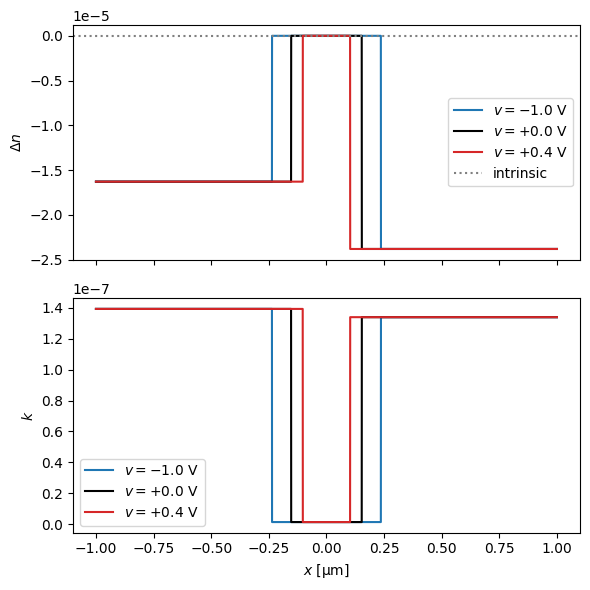

In [ ]:
# Refractive index change and extinction coefficient across the abrupt junction
x_um = np.linspace(-1.0, 1.0, 4001)
n_ref = refractive_index(N_I, N_I)         # intrinsic (depleted) silicon

fig, ax = plt.subplots(2, 1, figsize=(6, 6), sharex=True)
for v_bias, color in [(-1.0, "tab:blue"), (0.0, "black"), (0.4, "tab:red")]:
    prof = junction_profile(x_um, v_bias)
    ax[0].plot(x_um, refractive_index(prof["n"], prof["p"]) - n_ref, color=color, label=f"$v={v_bias:+.1f}$ V")
    ax[1].plot(x_um, extinction_coefficient(prof["n"], prof["p"]), color=color, label=f"$v={v_bias:+.1f}$ V")
ax[0].axhline(0, color="gray", linestyle=":", label="intrinsic")
ax[0].set_ylabel(r"$\Delta n$")
ax[0].legend()
ax[1].set_xlabel("$x$ [µm]")
ax[1].set_ylabel(r"$k$")
ax[1].legend()
fig.tight_layout()
plt.show()

## Lateral modes of the ridge

A ridge waveguide with a lateral p–n junction is analysed in the effective-index picture. The vertical structure (a Si layer of thickness 220 nm in SiO$_2$) is replaced by its effective index, $\varepsilon_{r}=N_\mathrm{slab}^2$, and the remaining **lateral** problem is one-dimensional: oxide | p-Si | n-Si | oxide with the junction at $x=0$. The dominant field of the quasi-TE wire mode is $E_x$, normal to the lateral interfaces, so the lateral problem is TM-type ($\psi=H_y$). The TE case ($\psi=E_y$) is also available.

For a mode $\propto e^{i\beta z}$ the scalar field $\psi(x)$ satisfies

$$\psi'' + \left(k_0^2\,\varepsilon_r(x) - \beta^2\right)\psi = 0,$$

with $\psi$ and $\psi'/s$ continuous across every interface, where $s=1$ (TE) or $s=\varepsilon_r$ (TM). With $u_j=\sqrt{k_0^2\varepsilon_j-\beta^2}$ in each layer and $\kappa=\sqrt{\beta^2-k_0^2\varepsilon_{ox}}$ in the oxide, the pair $(\psi,\psi'/s)$ is propagated through a layer of thickness $d$ by

$$M_j(d) = \begin{pmatrix} \cos u_j d & \dfrac{s_j}{u_j}\sin u_j d \\[2mm] -\dfrac{u_j}{s_j}\sin u_j d & \cos u_j d \end{pmatrix}.$$

Starting from a decaying field in the left oxide, $(\psi,\psi'/s)=(1,\kappa/s_{ox})$, and requiring decay in the right oxide gives the dispersion relation

$$F(\beta) = \left(\frac{\kappa}{s_{ox}},\,1\right)\cdot M_n(a_n)\,M_p(a_p)\cdot\begin{pmatrix}1\\ \kappa/s_{ox}\end{pmatrix} = 0, \qquad k_0\sqrt{\varepsilon_{ox}}<\beta<k_0\sqrt{\varepsilon_{\max}}.$$

For $\varepsilon_p=\varepsilon_n$ it reduces to the symmetric slab, $u\tan(ua)=\kappa r$ (even modes) and $u\cot(ua)=-\kappa r$ (odd modes), with $a$ the half width and $r=1$ (TE) or $\varepsilon_{Si}/\varepsilon_{ox}$ (TM). A depleted layer, as needed for the finite-$W$ check below, is just an additional entry in the list of layers.

Effective index of the 220 nm slab (TE0): N_SLAB = 2.8513
TM modes of the 500 nm ridge (W = 0):
  mode 0: n_eff = 2.49518
  mode 1: n_eff = 1.58926


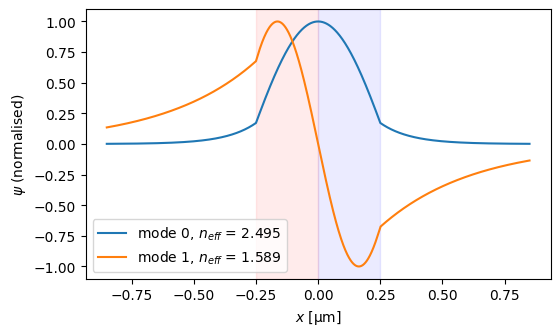

In [ ]:
# ---- Parameters of the ridge (lengths in um) ----
RIDGE_WIDTH_UM = 0.50          # ridge width
JUNCTION_OFFSET_UM = 0.0       # junction position relative to the ridge centre (> 0: wider p side)
SLAB_THICKNESS_UM = 0.22       # thickness of the vertical Si slab
N_OX = 1.4447                  # SiO2 refractive index
EPS_R_OX = N_OX**2
POLARIZATION = "TM"            # lateral polarization: "TM" (psi = H_y, quasi-TE wire mode) or "TE" (psi = E_y)
EIM_FACTOR = 1.0               # scales the carrier-induced Delta eps in the effective-index picture
                               # (~ overlap of the vertical slab mode with Si; 1 = bulk-like)


# ---- Transfer-matrix solver: continuity of psi and psi'/s (s = 1 for TE, s = eps_r for TM) ----
def _s_factor(eps_r, polarization):
    return eps_r if polarization == "TM" else 1.0


def _layer_matrix(eps_r, thickness, beta, polarization):
    """Maps (psi, psi'/s) across a uniform layer; eps_r real, lengths in um, beta in um^-1."""
    u = np.sqrt(complex(K0_UM**2 * eps_r - beta**2))
    sin_over_u = thickness if abs(u * thickness) < 1e-9 else np.sin(u * thickness) / u
    cos_ut, s = np.cos(u * thickness), _s_factor(eps_r, polarization)
    return np.array([[cos_ut, s * sin_over_u], [-u**2 * sin_over_u / s, cos_ut]])


def dispersion(beta, layers, polarization=POLARIZATION):
    """F(beta); guided modes are its zeros. layers = [(eps_r, thickness_um), ...] from left to right."""
    kappa = np.sqrt(beta**2 - K0_UM**2 * EPS_R_OX)
    s_ox = _s_factor(EPS_R_OX, polarization)
    state = np.array([1.0, kappa / s_ox], dtype=complex)           # decaying field in the left oxide
    for eps_r, thickness in layers:
        state = _layer_matrix(np.real(eps_r), thickness, beta, polarization) @ state
    return np.real(state[1] + kappa / s_ox * state[0])             # must match decay in the right oxide


def find_modes(layers, polarization=POLARIZATION, n_scan=4000):
    """All guided propagation constants beta [um^-1], fundamental mode first."""
    eps_max = max(np.real(eps_r) for eps_r, _ in layers)
    beta_scan = np.linspace(K0_UM * np.sqrt(EPS_R_OX) * (1 + 1e-9), K0_UM * np.sqrt(eps_max) * (1 - 1e-9), n_scan)
    f_scan = np.array([dispersion(b, layers, polarization) for b in beta_scan])
    roots = [brentq(dispersion, beta_scan[i], beta_scan[i + 1], args=(layers, polarization), xtol=1e-14)
             for i in range(n_scan - 1) if f_scan[i] * f_scan[i + 1] < 0]
    return np.array(roots[::-1])


def mode_profile(beta, layers, x_grid_um, x_left_um, polarization=POLARIZATION):
    """psi(x) and psi'(x) on x_grid_um; x_left_um is the left edge of the first layer. Unnormalised."""
    kappa = np.sqrt(beta**2 - K0_UM**2 * EPS_R_OX)
    s_ox = _s_factor(EPS_R_OX, polarization)
    psi, dpsi = np.zeros(x_grid_um.shape), np.zeros(x_grid_um.shape)

    left = x_grid_um < x_left_um
    psi[left] = np.exp(kappa * (x_grid_um[left] - x_left_um))
    dpsi[left] = kappa * psi[left]

    state = np.array([1.0, kappa / s_ox])                          # (psi, psi'/s) at the left edge
    edges = x_left_um + np.concatenate([[0.0], np.cumsum([d for _, d in layers])])
    for (eps_r, thickness), x0, x1 in zip(layers, edges[:-1], edges[1:]):
        eps_r = np.real(eps_r)
        s = _s_factor(eps_r, polarization)
        inside = (x_grid_um >= x0) & (x_grid_um < x1)
        xi = x_grid_um[inside] - x0
        u = np.sqrt(complex(K0_UM**2 * eps_r - beta**2))
        sin_over_u = np.where(np.abs(u * xi) < 1e-9, xi, np.sin(u * xi) / (u if u != 0 else 1))
        psi[inside] = np.real(state[0] * np.cos(u * xi) + state[1] * s * sin_over_u)
        dpsi[inside] = np.real(s * (-state[0] * u**2 * sin_over_u / s + state[1] * np.cos(u * xi)))
        state = np.real(_layer_matrix(eps_r, thickness, beta, polarization) @ state)

    right = x_grid_um >= edges[-1]
    psi[right] = state[0] * np.exp(-kappa * (x_grid_um[right] - edges[-1]))
    dpsi[right] = -kappa * psi[right]
    return psi, dpsi


# ---- Effective index of the vertical slab (TE0 of the Si layer in SiO2): core index of the lateral problem ----
N_SLAB = find_modes([(np.real(EPS_R_SI_OPT), SLAB_THICKNESS_UM)], "TE")[0] / K0_UM
print(f"Effective index of the {1e3 * SLAB_THICKNESS_UM:.0f} nm slab (TE0): N_SLAB = {N_SLAB:.4f}")

# ---- Permittivities of the lateral problem ----
n0_p, p0_p = equilibrium_densities(-N_A)          # quasi-neutral p side
n0_n, p0_n = equilibrium_densities(N_D)           # quasi-neutral n side
EPS_R_SLAB = N_SLAB**2
eps_r_p = EPS_R_SLAB + EIM_FACTOR * drude_delta_eps(n0_p, p0_p)
eps_r_n = EPS_R_SLAB + EIM_FACTOR * drude_delta_eps(n0_n, p0_n)
eps_r_d = EPS_R_SLAB + EIM_FACTOR * drude_delta_eps(N_I, N_I)     # depleted silicon


def ridge_layers(a_p, a_n, eps_p, eps_n, x_p=0.0, x_n=0.0, eps_d=eps_r_d):
    """Layers of the ridge [-a_p, a_n] with the junction at x = 0 and an optional depleted region [-x_p, x_n]."""
    layers = [(eps_p, a_p - x_p), (eps_d, x_p), (eps_d, x_n), (eps_n, a_n - x_n)]
    return [(eps_r, d) for eps_r, d in layers if d > 0]


# ---- Modes of the W = 0 ridge ----
a_p = RIDGE_WIDTH_UM / 2 + JUNCTION_OFFSET_UM     # p-side half width (junction at x = 0)
a_n = RIDGE_WIDTH_UM / 2 - JUNCTION_OFFSET_UM
layers_w0 = ridge_layers(a_p, a_n, eps_r_p, eps_r_n)
betas_w0 = find_modes(layers_w0)
beta_w0 = betas_w0[0]                              # fundamental mode
print(f"{POLARIZATION} modes of the {1e3 * RIDGE_WIDTH_UM:.0f} nm ridge (W = 0):")
for i, b in enumerate(betas_w0):
    print(f"  mode {i}: n_eff = {b / K0_UM:.5f}")

x_um = np.linspace(-a_p - 0.6, a_n + 0.6, 1500)
fig, ax = plt.subplots(figsize=(6, 3.5))
for i, b in enumerate(betas_w0[:3]):
    psi, _ = mode_profile(b, layers_w0, x_um, -a_p)
    ax.plot(x_um, psi / np.max(np.abs(psi)), label=f"mode {i}, $n_{{eff}}$ = {b / K0_UM:.3f}")
ax.axvspan(-a_p, 0, color="red", alpha=0.08)
ax.axvspan(0, a_n, color="blue", alpha=0.08)
ax.set_xlabel("$x$ [µm]")
ax.set_ylabel(r"$\psi$ (normalised)")
ax.legend()
plt.show()

## Perturbation by a finite depletion width

Taking the $W=0$ modes as unperturbed, a finite depletion region $[-x_p, x_n]$ changes the permittivity from the doped values $\varepsilon_p,\varepsilon_n$ to the depleted value $\varepsilon_d$, i.e. $\Delta\varepsilon_r(x)=\varepsilon_d-\varepsilon_{p,n}$ there. To first order the propagation constant shifts by

$$\delta\beta = \frac{\omega\varepsilon_0\int \Delta\varepsilon_r\,|\mathbf{E}|^2\,dx}{4P}, \qquad P=\frac{1}{2}\Re\int (\mathbf{E}\times\mathbf{H}^*)_z\,dx,$$

which, in terms of the scalar field of the unperturbed mode, becomes

$$\text{TE:}\quad \delta\beta = \frac{k_0^2\int \Delta\varepsilon_r\,\psi^2\,dx}{2\beta\int\psi^2\,dx}, \qquad\qquad \text{TM:}\quad \delta\beta = \frac{\int \Delta\varepsilon_r\,\left(\beta^2\psi^2+\psi'^2\right)/\varepsilon_r^2\,dx}{2\int\beta\,\psi^2/\varepsilon_r\,dx}.$$

Then $\Delta n_\mathrm{eff}=\Re(\delta\beta)/k_0$ and the power-loss change is $2\,\Im(\delta\beta)$. The fraction of the power flowing through the depletion region, $\Gamma_d$, is also reported. As a check, the structure with an explicit depleted layer is solved exactly (lossless) and compared with the first-order result.

{'TM': np.float64(2.49518), 'TE': np.float64(2.63283)} <- n_eff of the W = 0 fundamental modes
 v [V]  W [um] | TM: Gamma_d  dn_eff (1st)  dn_eff (exact)  dloss [dB/cm] | TE: Gamma_d  dn_eff (1st)  dn_eff (exact)  dloss [dB/cm] |
 -1.00   0.473 | TM:   0.949     2.464e-05       2.463e-05         -0.058 | TE:   0.922     2.444e-05       2.443e-05         -0.058 |
 -0.90   0.459 | TM:   0.945     2.426e-05       2.427e-05         -0.058 | TE:   0.912     2.417e-05       2.416e-05         -0.057 |
 -0.80   0.444 | TM:   0.941     2.389e-05       2.388e-05         -0.057 | TE:   0.900     2.386e-05       2.386e-05         -0.057 |
 -0.70   0.430 | TM:   0.935     2.348e-05       2.347e-05         -0.056 | TE:   0.887     2.352e-05       2.351e-05         -0.056 |
 -0.60   0.414 | TM:   0.927     2.302e-05       2.301e-05         -0.055 | TE:   0.871     2.311e-05       2.312e-05         -0.055 |
 -0.50   0.398 | TM:   0.917     2.251e-05       2.251e-05         -0.053 | TE:   0.855     2.2

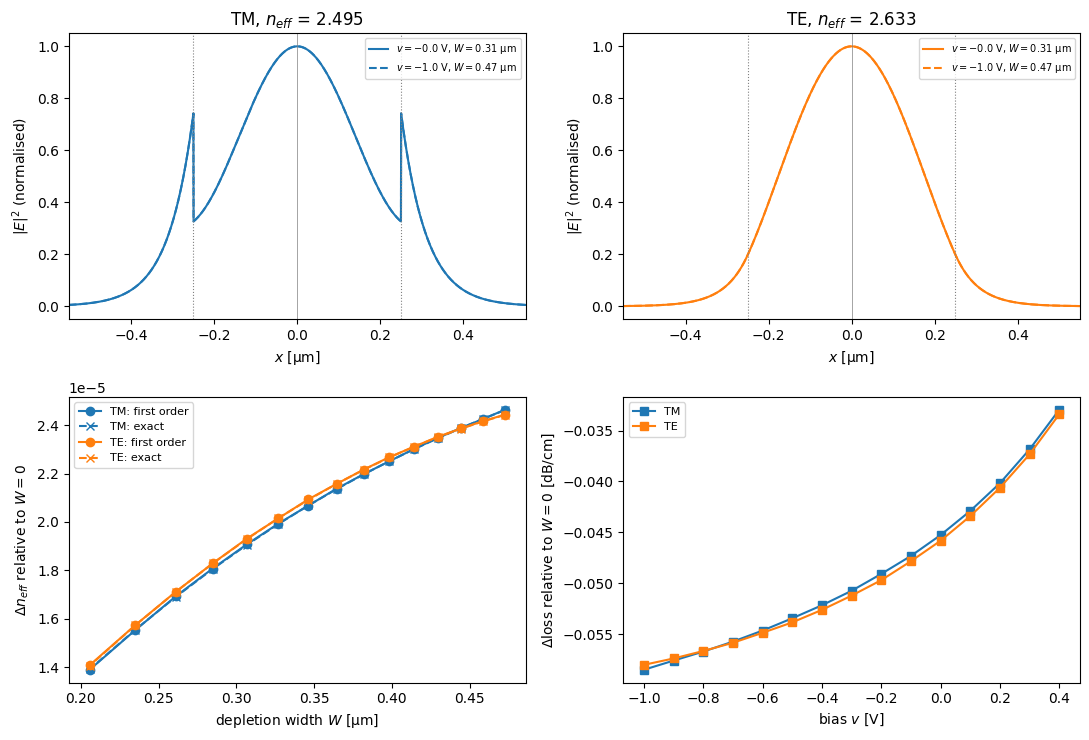

In [ ]:
_trapezoid = getattr(np, "trapezoid", None) or np.trapz


def depletion_perturbation(beta, a_p, a_n, x_p, x_n, polarization=POLARIZATION, n_points=6001):
    """First-order effect of a depletion region [-x_p, x_n] on a mode `beta` of the W = 0 ridge.

    Returns a dict with the complex shift d_beta [um^-1], the index change d_neff, the power-loss
    change [dB/cm], the fraction of power in the depleted region, and the |E|^2 profile.
    """
    layers = ridge_layers(a_p, a_n, eps_r_p, eps_r_n)
    kappa = np.sqrt(beta**2 - K0_UM**2 * EPS_R_OX)
    x_um = np.linspace(-a_p - 8 / kappa, a_n + 8 / kappa, n_points)
    psi, dpsi = mode_profile(beta, layers, x_um, -a_p, polarization)

    eps_local = np.where((x_um < -a_p) | (x_um > a_n), EPS_R_OX,
                         np.where(x_um < 0, np.real(eps_r_p), np.real(eps_r_n)))
    if polarization == "TM":
        e_squared = (beta**2 * psi**2 + dpsi**2) / eps_local**2
        power_density = beta * psi**2 / eps_local
        prefactor = 1.0
    else:
        e_squared = psi**2
        power_density = beta * psi**2
        prefactor = K0_UM**2

    delta_eps = np.zeros(x_um.shape, dtype=complex)
    delta_eps[(x_um >= -x_p) & (x_um < 0)] = eps_r_d - eps_r_p
    delta_eps[(x_um >= 0) & (x_um < x_n)] = eps_r_d - eps_r_n

    d_beta = prefactor * _trapezoid(delta_eps * e_squared, x_um) / (2 * _trapezoid(power_density, x_um))
    depleted = (x_um >= -x_p) & (x_um < x_n)
    return dict(d_beta=d_beta,
                d_neff=d_beta / K0_UM,
                d_loss_db_cm=4.343 * 2 * np.imag(d_beta) * 1e4,    # um^-1 -> cm^-1, power loss
                power_fraction=_trapezoid(power_density[depleted], x_um[depleted]) / _trapezoid(power_density, x_um),
                x_um=x_um, e_squared=e_squared)


# ---- Bias sweep (v_bias > 0: forward) for both lateral polarizations ----
POLARIZATIONS = ("TM", "TE")
POLARIZATION_COLORS = {"TM": "tab:blue", "TE": "tab:orange"}
v_sweep = np.linspace(-1.0, 0.4, 15)
beta_w0_by_polarization = {pol: find_modes(layers_w0, pol)[0] for pol in POLARIZATIONS}

sweep = {}
for polarization in POLARIZATIONS:
    beta_0 = beta_w0_by_polarization[polarization]
    rows = []
    for v_bias in v_sweep:
        x_p, x_n = depletion_widths(v_bias)
        if x_p >= a_p or x_n >= a_n:                    # depletion region would exceed the ridge
            rows.append(None)
            continue
        res = depletion_perturbation(beta_0, a_p, a_n, x_p, x_n, polarization)
        # Exact (lossless) re-solution with an explicit depleted layer, to check the first-order result
        layers_exact = ridge_layers(a_p, a_n, np.real(eps_r_p), np.real(eps_r_n), x_p, x_n, np.real(eps_r_d))
        res["d_neff_exact"] = (find_modes(layers_exact, polarization)[0] - beta_0) / K0_UM
        res["width_um"] = x_p + x_n
        rows.append(res)
    sweep[polarization] = rows

valid = [i for i, r in enumerate(sweep["TM"]) if r is not None]     # same biases for both polarizations
v_valid = v_sweep[valid]
width_um = np.array([sweep["TM"][i]["width_um"] for i in valid])


def sweep_array(polarization, key):
    """Real part of `key` over the valid biases for the given polarization."""
    return np.array([np.real(sweep[polarization][i][key]) for i in valid])


print({pol: round(beta_w0_by_polarization[pol] / K0_UM, 5) for pol in POLARIZATIONS}, "<- n_eff of the W = 0 fundamental modes")
header = f"{'v [V]':>6} {'W [um]':>7} |" + "".join(
    f" {pol}: {'Gamma_d':>7} {'dn_eff (1st)':>13} {'dn_eff (exact)':>15} {'dloss [dB/cm]':>14} |" for pol in POLARIZATIONS)
print(header)
for j in range(len(valid)):
    line = f"{v_valid[j]:6.2f} {width_um[j]:7.3f} |"
    for pol in POLARIZATIONS:
        line += (f" {pol}: {sweep_array(pol, 'power_fraction')[j]:7.3f} {sweep_array(pol, 'd_neff')[j]:13.3e}"
                 f" {sweep_array(pol, 'd_neff_exact')[j]:15.3e} {sweep_array(pol, 'd_loss_db_cm')[j]:14.3f} |")
    print(line)

fig, ax = plt.subplots(2, 2, figsize=(11, 7.5))
# Top row: |E|^2 of the fundamental mode, TM (left) and TE (right)
for col, polarization in enumerate(POLARIZATIONS):
    for i, linestyle in [(valid[np.argmin(np.abs(v_valid))], "-"), (valid[0], "--")]:
        r = sweep[polarization][i]
        ax[0][col].plot(r["x_um"], r["e_squared"] / np.max(r["e_squared"]), linestyle,
                        color=POLARIZATION_COLORS[polarization],
                        label=f"$v={v_sweep[i]:.1f}$ V, $W={r['width_um']:.2f}$ µm")
    ax[0][col].axvline(-a_p, color="gray", linewidth=0.8, linestyle=":")
    ax[0][col].axvline(a_n, color="gray", linewidth=0.8, linestyle=":")
    ax[0][col].axvline(0, color="gray", linewidth=0.5)
    ax[0][col].set_xlim(-a_p - 0.3, a_n + 0.3)
    ax[0][col].set_xlabel("$x$ [µm]")
    ax[0][col].set_ylabel(r"$|E|^2$ (normalised)")
    ax[0][col].set_title(f"{polarization}, $n_{{eff}}$ = {beta_w0_by_polarization[polarization] / K0_UM:.3f}")
    ax[0][col].legend(fontsize=7)
# Bottom row: effect of the depletion width
for polarization in POLARIZATIONS:
    color = POLARIZATION_COLORS[polarization]
    ax[1][0].plot(width_um, sweep_array(polarization, "d_neff"), "o-", color=color, label=f"{polarization}: first order")
    ax[1][0].plot(width_um, sweep_array(polarization, "d_neff_exact"), "x--", color=color, label=f"{polarization}: exact")
    ax[1][1].plot(v_valid, sweep_array(polarization, "d_loss_db_cm"), "s-", color=color, label=polarization)
ax[1][0].set_xlabel("depletion width $W$ [µm]")
ax[1][0].set_ylabel(r"$\Delta n_{eff}$ relative to $W=0$")
ax[1][0].legend(fontsize=8)
ax[1][1].set_xlabel("bias $v$ [V]")
ax[1][1].set_ylabel(r"$\Delta$loss relative to $W=0$ [dB/cm]")
ax[1][1].legend(fontsize=8)
fig.tight_layout()
plt.show()